# Evaluation of the three models on ART (αNLI)

NLP HS26, Course Project 2 - Gabriel Gjonaj

This notebook computes every number and figure of the evaluation from the files in `runs/`:
`results.json` (accuracy, loss and confusion matrix per split), `predictions_<split>.csv` (one row per example)
and `metrics/version_0/metrics.csv` (loss and accuracy per epoch). No model is trained and no request is sent
to the LLM. The functions are in `artp2/analysis.py`, the figures are saved to `results/figures/`.

| | model | final configuration |
|---|---|---|
| 1 | `roberta-base` architecture, random weights | lr 2e-5, up to 30 epochs, 4 seeds |
| 2 | `roberta-base`, pretrained | lr 1e-5, up to 5 epochs, 4 seeds |
| 3 | Qwen3 235B Instruct (LLM, hosted) | prompt with 8 solved training examples, temperature 0, one run |

Sections 1 to 6 end with **Observations**: they only describe what the numbers show.
The **interpretation** follows in section 7.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import pandas as pd
from datasets import disable_progress_bars

from artp2 import analysis
from artp2.analysis import M1, M2, M3, MODELS
from artp2.data import load_art

plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_colwidth", None)
disable_progress_bars()


def table(rows, digits=None):
    """Show a list of rows as a table with 1 decimal; digits = {column: decimals} for exceptions."""
    frame = pd.DataFrame(rows)
    return frame.round({column: (digits or {}).get(column, 1) for column in frame.columns})


ds = load_art()
{name: len(split) for name, split in ds.items()}

{'train': 16801, 'validation': 1000, 'test': 1532}

## 1 Accuracy on train, validation and test

Accuracy in percent. Models 1 and 2: mean and standard deviation (sd) over 4 seeds.
Model 3: one run; its train value is measured on 1,000 sampled training examples (none of them is one of the 8 examples in the prompt).

In [2]:
accuracy = analysis.accuracy_table(ds)
table(accuracy)

,model,runs,train,train sd,validation,validation sd,test,test sd
0,Majority class,0,50.4,0.0,50.8,0.0,51.0,0.0
1,Model 1 · random weights,4,77.5,2.5,66.6,1.0,53.4,0.6
2,Model 2 · pretrained,4,97.8,1.3,89.9,0.3,67.3,0.4
3,Model 3 · LLM,1,95.4,0.0,96.1,0.0,87.3,0.0


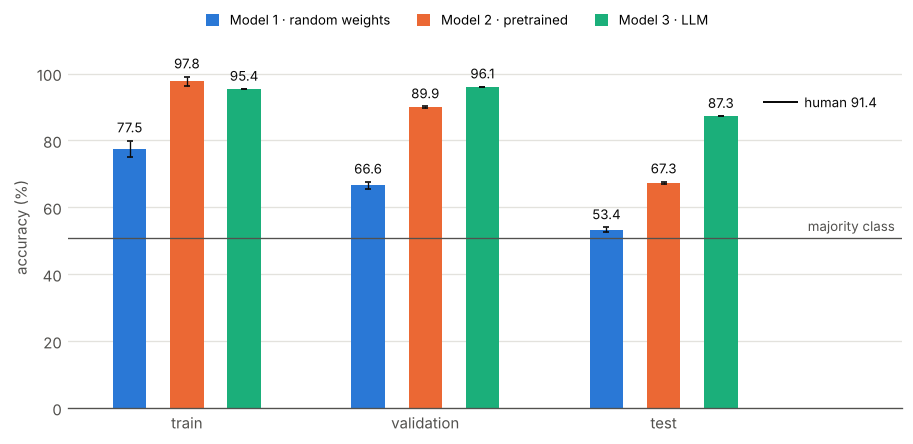

In [3]:
analysis.plot_accuracy(accuracy);

The difference between validation and test, and the uncertainty of the single LLM run
(95 % interval of an accuracy measured on n examples):

In [4]:
table(analysis.gap_table(accuracy))

,model,validation,test,gap
0,Majority class,50.8,51.0,-0.2
1,Model 1 · random weights,66.6,53.4,13.2
2,Model 2 · pretrained,89.9,67.3,22.6
3,Model 3 · LLM,96.1,87.3,8.8


In [5]:
llm = analysis.results(MODELS[M3][0])
table([{"split": split, "examples": llm[split]["n"], "accuracy": 100 * llm[split]["acc"],
        "95 % interval +-": analysis.interval(100 * llm[split]["acc"], llm[split]["n"]),
        "invalid answers": llm[split]["invalid"]} for split in analysis.SPLITS])

,split,examples,accuracy,95 % interval +-,invalid answers
0,train,1000,95.4,1.3,1
1,validation,1000,96.1,1.2,2
2,test,1532,87.3,1.7,0


**Observations**

* The majority class reaches 50.4 / 50.8 / 51.0 % on train / validation / test.
* Test accuracy: model 1 53.4 ± 0.6, model 2 67.3 ± 0.4, model 3 87.3 (95 % interval ± 1.7). Model 2 is 14.0 points above model 1, model 3 is 19.9 points above model 2 and 4.1 points below the human performance of 91.4 %.
* Model 1 is 2.4 points above the majority class on test.
* Every model is lower on test than on validation: by 13.2 (model 1), 22.6 (model 2) and 8.8 points (model 3).
* Model 2 has the highest train accuracy (97.8) and the largest difference between train and test (30.4 points).
* The seeds differ little: the standard deviation on test is 0.6 (model 1) and 0.4 points (model 2).

## 2 Confusion matrices

Rows: correct hypothesis, columns: predicted hypothesis. Each cell shows the number of examples and the share of its row.
Models 1 and 2: seed 42. Invalid LLM answers count as wrong but have no column (validation: 2, test: 0).

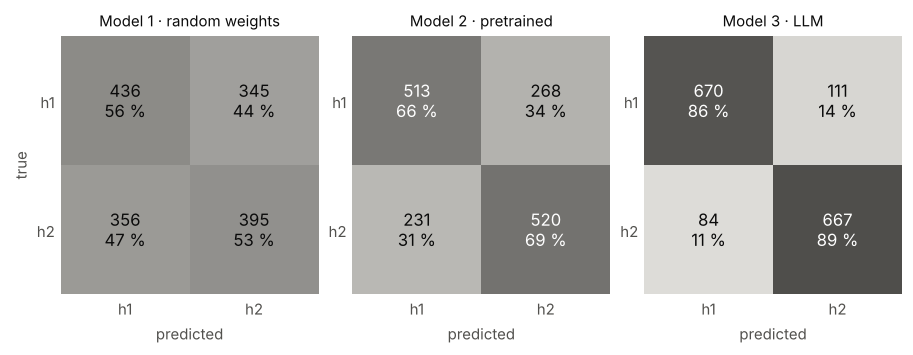

In [6]:
analysis.plot_confusion("test");

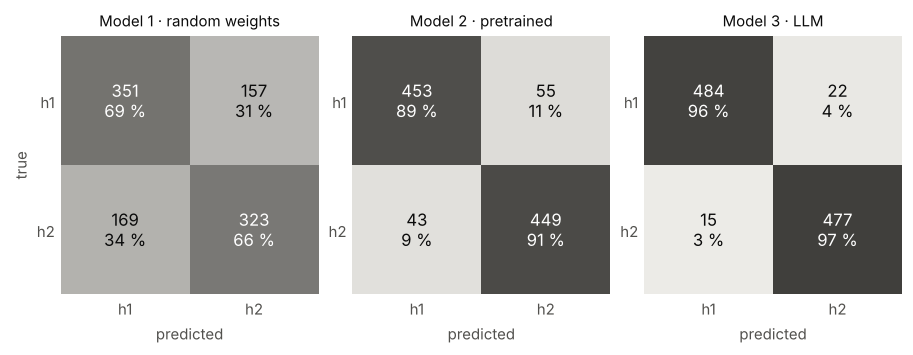

In [7]:
analysis.plot_confusion("validation");

In [8]:
rows = []
for name, runs in MODELS.items():
    matrix = analysis.confusion(runs[0], "test")
    total = sum(map(sum, matrix))
    rows.append({"model": name, "h1 is correct (%)": 100 * sum(matrix[0]) / total,
                 "h1 is predicted (%)": 100 * (matrix[0][0] + matrix[1][0]) / total})
table(rows)

,model,h1 is correct (%),h1 is predicted (%)
0,Model 1 · random weights,51.0,51.7
1,Model 2 · pretrained,51.0,48.6
2,Model 3 · LLM,51.0,49.2


**Observations**

* On test, h1 is the correct hypothesis in 51.0 % of the examples. The models predict h1 in 51.7 % (model 1), 48.6 % (model 2) and 49.2 % (model 3) of the examples.
* The errors are spread over both classes. On test, 56 / 53 % (model 1), 66 / 69 % (model 2) and 86 / 89 % (model 3) of the h1 / h2 examples are correct: the two rows differ by 3 to 4 points for every model.

## 3 Training of models 1 and 2

Learning rate search with seed 42. The best epoch is the epoch with the highest validation accuracy (epochs are counted from 0);
train, validation and test are measured with the weights of that epoch.

In [9]:
table(analysis.lr_table(), {"validation loss": 3})

,model,learning rate,best epoch,train,validation,test,validation loss
0,Model 2 · pretrained,1e-05,4,98.5,90.2,67.4,0.368
1,Model 2 · pretrained,2e-05,1,97.4,88.9,65.2,0.298
2,Model 2 · pretrained,3e-05,3,99.8,90.2,66.4,0.423
3,Model 2 · pretrained,5e-05,2,99.6,89.5,67.2,0.417
4,Model 1 · random weights,1e-05,5,79.0,67.0,53.8,0.629
5,Model 1 · random weights,2e-05,3,78.3,67.4,54.2,0.625
6,Model 1 · random weights,5e-05,2,78.3,66.4,53.2,0.656
7,Model 1 · random weights,1e-04,0,62.9,60.0,52.0,0.692


For model 2 the two learning rates with the highest validation accuracy were repeated with 4 seeds:

In [10]:
rows = []
for lr in ("1e-05", "3e-05"):
    mean, sd = analysis.mean_sd([f"pre-lr{lr}-s{seed}" for seed in analysis.SEEDS], "validation")
    rows.append({"model": M2, "learning rate": lr, "seeds": len(analysis.SEEDS), "validation": mean, "validation sd": sd})
table(rows)

,model,learning rate,seeds,validation,validation sd
0,Model 2 · pretrained,1e-05,4,89.9,0.3
1,Model 2 · pretrained,3e-05,4,89.7,0.4


Loss and accuracy per epoch for the final configurations, one line per seed. The train values are averaged over the epoch
(while the weights change), the validation values are measured at the end of the epoch.

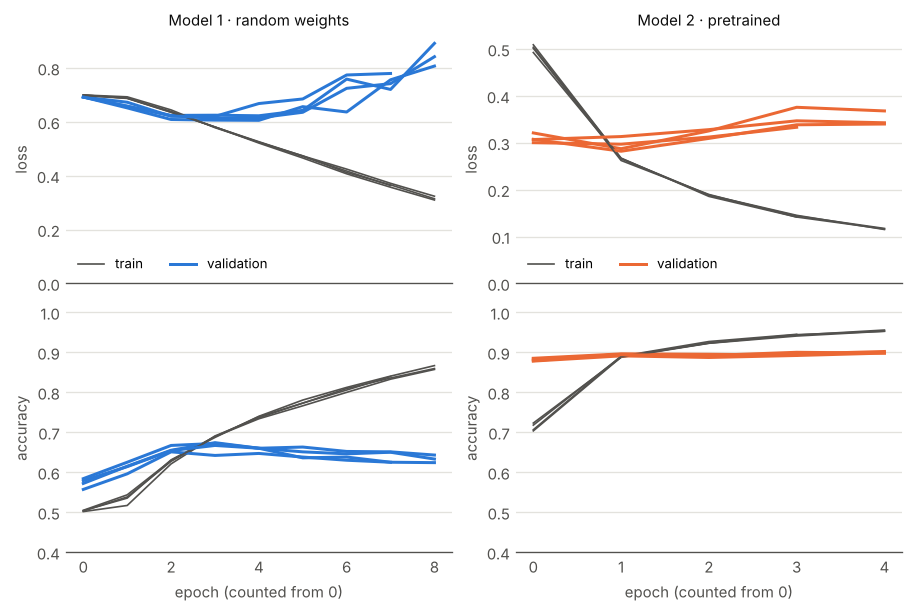

In [11]:
analysis.plot_curves();

**Observations**

* Model 2 reaches 88.9 to 90.2 % validation accuracy with every learning rate from 1e-5 to 5e-5. With 4 seeds, 1e-5 gives 89.9 ± 0.3 and 3e-5 gives 89.7 ± 0.4.
* Model 1 reaches 66.4 to 67.4 % with 1e-5 to 5e-5. With 1e-4 the best epoch is the first one (60.0 % validation, 62.9 % train).
* Model 2 is at 88 % validation accuracy after the first epoch and gains about 1 to 2 points afterwards. Its validation loss is lowest in epoch 0 or 1 and rises afterwards, while the train loss keeps falling.
* Model 1 reaches its best validation accuracy (65 to 67 %) in epoch 2 or 3. Afterwards the validation loss rises from about 0.61 to 0.78 or more, while the train accuracy keeps rising (to 84 to 87 %).

## 4 Ablations

Each variant changes one factor against the reference run (seed 42, one run per variant).
*Hypothesis only*: the model sees the two hypotheses without the observations.

In [12]:
table(analysis.ablation_table())

,variant,Model 1 · random weights · validation,Model 1 · random weights · test,Model 2 · pretrained · validation,Model 2 · pretrained · test
0,Reference run,67.4,54.2,90.2,67.4
1,"Segment order: O1 O2, then hypothesis",66.1,54.1,88.2,67.4
2,Mean pooling instead of the <s> vector,66.3,53.9,90.0,67.0
3,Hypothesis only,67.8,52.5,78.5,58.9
4,"4,000 training examples",62.7,51.7,87.3,63.8
5,"1,000 training examples",53.1,50.8,84.1,59.4
6,Classifier learning rate 1e-3,NaN,NaN,90.0,65.9
7,10 instead of 5 epochs,NaN,NaN,89.9,67.4


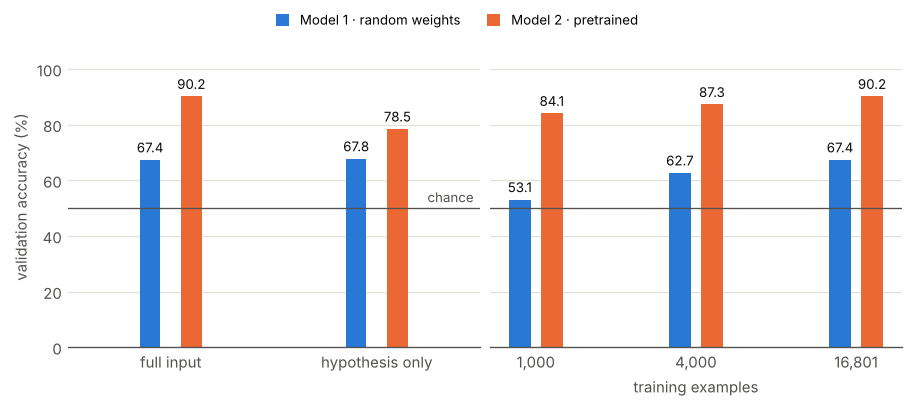

In [13]:
analysis.plot_ablations();

**Observations**

* Without the observations, model 1 reaches 67.8 % on validation (reference: 67.4 %). Model 2 falls from 90.2 to 78.5 %.
* On test, the hypothesis-only models reach 52.5 % (model 1) and 58.9 % (model 2).
* With 1,000 / 4,000 / 16,801 training examples model 1 reaches 53.1 / 62.7 / 67.4 % on validation, model 2 84.1 / 87.3 / 90.2 %. Model 2 with 1,000 examples is 16.7 points above model 1 with all examples.
* Segment order and pooling change the validation accuracy by 0.2 to 2.0 points. The largest change is the segment order for model 2 (88.2 instead of 90.2 %); on test it makes no difference (67.4 %).
* A classifier learning rate of 1e-3 and 10 instead of 5 epochs change the validation accuracy of model 2 by 0.2 and 0.3 points.
* For comparison, the standard deviation over the seeds on validation is 1.0 (model 1) and 0.3 points (model 2).

## 5 Model 3: choice of the LLM and of the prompt

The choice was made on the validation split only, in two steps. All runs use temperature 0.
An answer without a readable 1 or 2 is invalid and counts as wrong.

**Step 1** - five models, zero-shot, the same 200 validation examples:

In [14]:
table(analysis.pilot_table())

,model,examples,validation,interval,invalid,tokens out
0,meta-llama/Llama-3.3-70B-Instruct,200,95.5,2.9,0,400
1,deepseek-ai/DeepSeek-V4-Pro,200,96.0,2.7,0,401
2,openai/gpt-oss-120b,200,98.0,1.9,0,25718
3,Qwen/Qwen3-235B-A22B-Instruct-2507,200,98.0,1.9,0,400
4,zai-org/GLM-5.2,200,98.5,1.7,1,29528


**Step 2** - prompt formats on all 1,000 validation examples: zero-shot, few-shot with 4 and 8 solved training examples,
step by step (`cot`), zero-shot with the two hypotheses swapped (`zero-swap`) and a second model.
The last columns compare every run with `qwen3-235b-zero` on the same examples (exact McNemar test).

In [15]:
prompts = analysis.prompt_table()
table(prompts, {"p": 2})

,run,validation,interval,invalid,tokens out,only this run right,only zero-shot right,p,same answer as zero-shot
0,qwen3-235b-zero,95.3,1.3,0,2000,0,0,1.00,100.0
1,qwen3-235b-few4,95.8,1.2,0,2000,22,17,0.52,96.1
2,qwen3-235b-few8,96.1,1.2,2,2012,22,14,0.24,96.4
3,qwen3-235b-cot,95.8,1.2,10,300965,23,18,0.53,95.8
4,qwen3-235b-zero-swap,95.7,1.3,0,2000,25,21,0.66,95.4
5,gpt-oss-120b-zero,95.5,1.3,0,131076,29,27,0.89,94.4


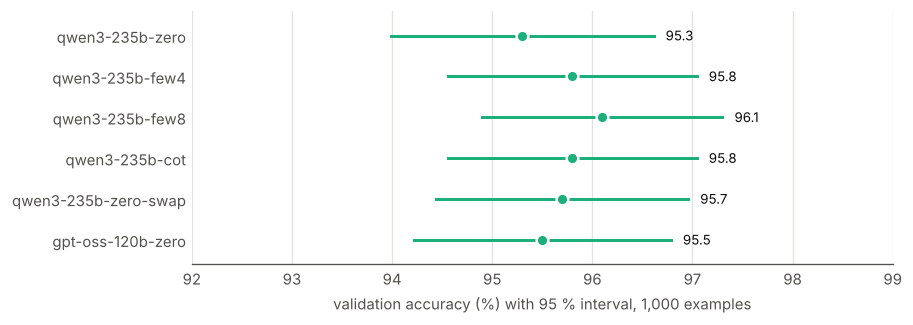

In [16]:
analysis.plot_prompts(prompts);

The invalid answers of the final run (`llm-qwen3-235b-few8`), with the last 40 characters of the answer:

In [17]:
table([{"split": split, **row} for split in analysis.SPLITS for row in analysis.invalid_answers(MODELS[M3][0], split)])

,split,index,end of the answer
0,train,15232,er middle is plausible given the ending.
1,validation,433,ddle is plausible because both imply the
2,validation,484,"er middle is plausible, as both conflict"


**Observations**

* Step 1: the five models reach 95.5 to 98.5 % on 200 examples. The 95 % intervals are ± 1.7 to ± 2.9 points and overlap.
* Step 2: all six runs reach 95.3 to 96.1 % on 1,000 examples, with intervals of ± 1.2 to ± 1.3 points. Few-shot with 8 examples has the highest value (96.1 %). No run differs measurably from zero-shot (p = 0.24 to 0.89).
* Qwen3 zero-shot reaches 95.3 % on 1,000 examples; on the 200 examples of step 1 it reached 98.0 %.
* With swapped hypotheses the accuracy is 95.7 instead of 95.3 %; 95.4 % of the answers are the same.
* The step-by-step prompt produces 150 times more output tokens (300,965 instead of 2,000) and 10 invalid answers.
* The final run has 1 invalid answer on the train sample, 2 on validation and 0 on test. In all three invalid answers the model does not choose: it writes that neither middle is plausible.

## 6 Error analysis

### 6.1 Negation words in the hypotheses

Each example is put into a group by where a negation word occurs (*not, no, never, nothing, nobody, cannot* and every
contraction that ends in *n't*): only in the wrong hypothesis, only in the correct hypothesis, in neither or in both.
Accuracy per group; models 1 and 2 as the mean of 4 seeds.

In [18]:
negation = analysis.negation_table(ds)
table(negation)

,split,negation word,pairs,Model 1 · random weights,Model 2 · pretrained,Model 3 · LLM
0,validation,only in the wrong hypothesis,120,94.4,94.2,95.8
1,validation,only in the correct hypothesis,53,21.7,83.0,94.3
2,validation,in neither hypothesis,780,65.3,89.4,96.4
3,validation,in both hypotheses,47,68.6,94.7,93.6
4,test,only in the wrong hypothesis,153,86.3,75.2,88.2
5,test,only in the correct hypothesis,146,22.8,57.9,90.4
6,test,in neither hypothesis,1201,53.1,67.5,86.8
7,test,in both hypotheses,32,43.8,64.8,84.4


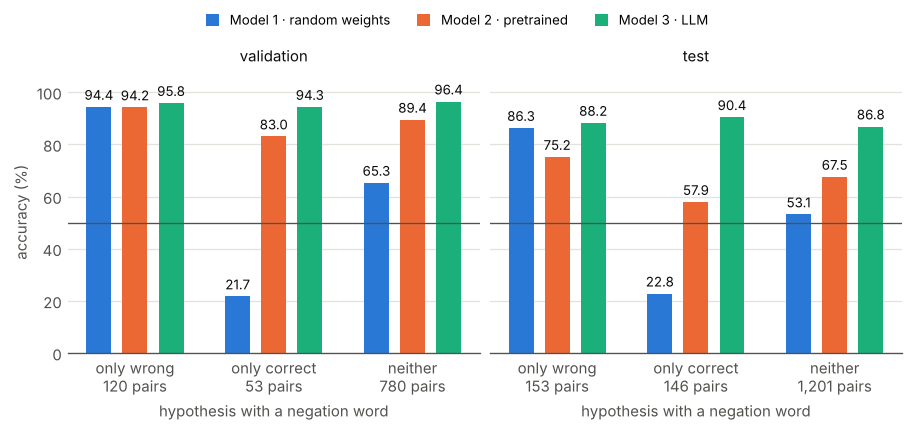

In [19]:
analysis.plot_negation(negation);

**Observations**

* Model 1 is correct in 94.4 % (validation) and 86.3 % (test) of the pairs where only the wrong hypothesis contains a negation word, and in 21.7 % and 22.8 % of the pairs where only the correct hypothesis contains one.
* Model 2 shows the same direction with a smaller difference: 94.2 and 83.0 % on validation, 75.2 and 57.9 % on test.
* Model 3 differs by at most 3.6 points between the three larger groups: 95.8 / 94.3 / 96.4 % on validation and 88.2 / 90.4 / 86.8 % on test.
* Pairs with a negation word only in the correct hypothesis make up 5.3 % of validation (53 of 1,000) and 9.5 % of test (146 of 1,532).
* In the pairs without a negation word, which are 78 % of each split, model 1 reaches 65.3 % on validation and 53.1 % on test.

### 6.2 Confidence of models 1 and 2

Confidence = the probability that the model gives to the hypothesis it predicts (between 0.5 and 1).
Share of the predictions and accuracy per confidence bin, all 4 seeds together.

In [20]:
rows = []
for name in (M1, M2):
    for split in ("validation", "test"):
        for row in analysis.confidence_table(MODELS[name], split):
            rows.append({"model": name, "split": split, "confidence": row["confidence"],
                         "share of predictions (%)": row["share"], "accuracy (%)": row["accuracy"]})
pd.DataFrame(rows).pivot(index=["model", "split"], columns="confidence").round(1)

share of predictions (%)             \
confidence                                        0.5 to 0.6 0.6 to 0.7   
model                    split                                            
Model 1 · random weights test                           23.4       22.3   
                         validation                     37.5       23.7   
Model 2 · pretrained     test                            8.5        7.5   
                         validation                      5.3        5.1   

                                                                      \
confidence                          0.7 to 0.8 0.8 to 0.9 0.9 to 1.0   
model                    split                                         
Model 1 · random weights test             19.3       17.9       17.1   
                         validation       15.7       11.1       12.0   
Model 2 · pretrained     test              8.8       10.6       64.6   
                         validation        5.0        7.4       77.2   

                                    accuracy (%)                        \
confidence                            0.5 to 0.6 0.6 to 0.7 0.7 to 0.8   
model                    split                                           
Model 1 · random weights test               51.2       50.4       54.4   
                         validation         57.9       62.5       68.2   
Model 2 · pretrained     test               53.0       53.6       58.0   
                         validation         66.7       68.5       75.5   

                                                           
confidence                          0.8 to 0.9 0.9 to 1.0  
model                    split                             
Model 1 · random weights test             54.9       57.4  
                         validation       77.2       90.0  
Model 2 · pretrained     test             58.8       73.5  
                         validation       80.7       94.7

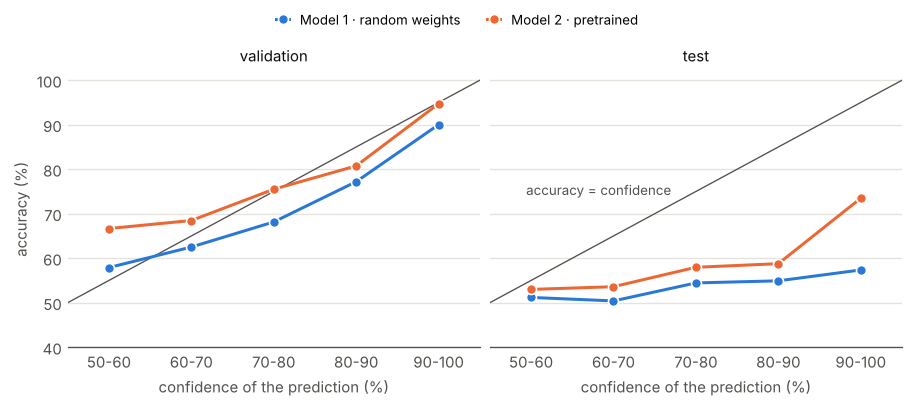

In [21]:
analysis.plot_confidence();

**Observations**

* On validation, the accuracy rises with the confidence for both models. The predictions of model 2 with a confidence of 0.9 or more (77.2 % of all) are correct in 94.7 % of the cases.
* On test, model 2 makes 64.6 % of its predictions with a confidence of 0.9 or more; 73.5 % of them are correct. In the bins below 0.9 its accuracy is between 53.0 and 58.8 %.
* On test, the accuracy of model 1 is between 50.4 and 57.4 % in every bin.

### 6.3 Which examples do the models solve?

Comparison of two models on the same test examples (models 1 and 2: seed 42).

In [22]:
pairs = [(M1, M2), (M2, M3), (M1, M3)]
table([{"first": first, "second": second, **analysis.overlap(MODELS[first][0], MODELS[second][0], "test")} for first, second in pairs])

,first,second,both right,only the first right,only the second right,both wrong
0,Model 1 · random weights,Model 2 · pretrained,617,214,416,285
1,Model 2 · pretrained,Model 3 · LLM,940,93,397,102
2,Model 1 · random weights,Model 3 · LLM,726,105,611,90


In [23]:
llm_right = analysis.correct(MODELS[M3][0], "test")
llm_errors = [index for index, right in llm_right.items() if not right]
seeds_right = [analysis.correct(run, "test") for run in MODELS[M2]]
{"errors of model 3": len(llm_errors),
 "wrong for all 4 seeds of model 2": sum(not any(seed[index] for seed in seeds_right) for index in llm_errors),
 "solved by at least one seed of model 2": sum(any(seed[index] for seed in seeds_right) for index in llm_errors)}

{'errors of model 3': 195,
 'wrong for all 4 seeds of model 2': 80,
 'solved by at least one seed of model 2': 115}

**Observations**

* Model 3 solves 397 test examples that model 2 does not solve; model 2 solves 93 that model 3 does not solve. 102 examples are solved by neither.
* Model 2 solves 416 examples that model 1 does not solve, model 1 solves 214 that model 2 does not solve.
* Of the 195 errors of model 3, 80 are also wrong for all 4 seeds of model 2 and 115 are solved by at least one seed.

### 6.4 Examples

The five test examples where model 2 (seed 42) gives the lowest probability to the correct hypothesis:

In [24]:
confident = analysis.confident_errors(MODELS[M2][0], "test", 5)
pd.DataFrame(analysis.examples(ds, "test", confident)).set_index("index").T

index,258,1045,1230,1257,446
observation 1,Rupert worked as a program leader keeping track of schedules.,Shirley was pregnant and had just gone into labor.,Pam does surveys daily to try to win prizes on Survey Monkey.,Trevor went to the lake one day to fish.,Our friend owns a restaurant.
correct hypothesis,Rupert hates his job.,Shirley barely experienced pain.,Pam wasted time with doing her surveys.,The water was perfect for all levels of fishing.,Our friend kept the restaurant open after hours.
wrong hypothesis,Rupert loves his job.,Shirley was excited she was going to become a mom.,Pam tried her best to be as honest as possible.,The water was spitting up poles.,Our friend tried to impress the employees with a free meal.
observation 2,Rupert is glad that he is so close to retirement.,"Before she could wrap her head around it, her baby was born.",Pam did not seem to think there was anything wrong with that.,Trevor was forced to go home after he lost his fishing pole.,The employee was not impressed.
Model 1 · random weights · p(correct),0.114,0.272,0.138,0.232,0.026
Model 2 · pretrained · p(correct),0.0,0.0,0.0,0.0,0.0
Model 3 · LLM,right,right,right,right,wrong


The two examples used on the slides (negation word only in the correct hypothesis):

In [25]:
pd.DataFrame(analysis.examples(ds, "test", [389, 967])).set_index("index").T

index,389,967
observation 1,Dave's parents have a restaurant.,Tracy's cat was named Bob.
correct hypothesis,Dave's restaurant was no longer doing well.,"Tracy would never give her cat, Bob a bath."
wrong hypothesis,They are getting more customers.,Tracy used an expensive vet treatment on her cat.
observation 2,They decided to close the business.,Bob still has fleas.
Model 1 · random weights · p(correct),0.016,0.002
Model 2 · pretrained · p(correct),1.0,0.0
Model 3 · LLM,right,right


**Observations**

* In the five examples model 2 gives the correct hypothesis a probability below 0.001. Model 3 answers four of the five correctly.
* In example 258 the two hypotheses differ in one word (*hates* / *loves*).
* In examples 389 and 967 the correct hypothesis contains *no longer* and *never*. Model 1 gives it a probability of 0.02 and 0.00; model 2 is right in 389 (1.00) and wrong in 967 (0.00); model 3 is right in both.

## 7 Interpretation

**Pretraining matters more than training on the task.**

1. *Model 1 learns cues in the hypotheses, not the task.* Without the observations it is as good as with them (section 4), and it mostly picks the hypothesis without a negation word (section 6.1). 16,801 examples are not enough to learn language from scratch, so the model uses what can be learned from few examples: surface properties of the hypotheses. On the test split these cues help less, and the model is close to the majority class.
2. *Model 2 uses the observations and needs little data.* Without the observations it loses 11.7 points on validation, and with 1,000 examples it is far above model 1 with all examples (section 4). The language knowledge comes from pretraining; finetuning only has to add the task. It still relies partly on the same cues: on test it is 17 points better when the negation word is in the wrong hypothesis than when it is in the correct one, and it is confident in many of its errors (section 6.2).
3. *The LLM solves the task without training on it.* With 8 examples in the prompt it is 20 points above model 2 on test and 4 points below the human performance. Its accuracy does not depend on where the negation word is. The prompt format matters little: all formats are within one point on validation, which is inside the uncertainty of the measurement (section 5).
4. *The test split is harder for every model.* The test pairs were filtered with BERT as the adversary, the validation split is a held-out part of the training pairs. Model 2 loses the most (22.6 points): part of what it learned are properties of the training pairs that do not hold for the filtered test pairs. Model 1 cannot lose much more, it ends near the majority class. The LLM was not trained on the training pairs and still loses 9 points, so the test pairs are not only different, they are also harder.

**Compared with the expectations** (`EXPECTATIONS.md`, written before the first experiment)

| model | expected validation | measured | expected test | measured |
|---|---|---|---|---|
| 1 | 55-68 | 66.6 | 50-54 | 53.4 |
| 2 | 80-88 | 89.9 | 68-75 | 67.3 |
| 3 | 88-94 | 96.1 | 84-90 | 87.3 |

Model 2 and the LLM are about 2 points above the expected range on validation, and model 2 is 0.7 points below the range on test. I underestimated how large the difference between validation and test is for model 2 (22.6 points).

**Limits**

* Model 3 is one model with one run, and the choice between the prompt formats was made between differences that are not measurable.
* ART is public since 2019. The LLM may have seen the data in its pretraining, so its accuracy can overestimate its reasoning ability.
* The negation word is one cue that I looked for. The hypothesis-only result of model 2 (78.5 % on validation) shows that there are more.
* Ablations and the learning rate search use one seed; differences below about 1 point (model 2) and 3 points (model 1) are within the variation between seeds.